# Input DX Codes and Generate Base Files

This script creates the backbone of the dataset, which is to use DX code frequencies to generate a dataset with one observation per theoretical stay.  The constant OUTPUT_ROWS in 00_setup.py determines how many visits to generate.

In addition to the above, code reference tables are generated for the ICD-10 diagnoses and the CCS categories.

In [1]:
# Modify the file 00_setup.py to define input/output file paths on your system
from importlib.machinery import SourceFileLoader
setup = SourceFileLoader("setup", "./00_setup.py").load_module()

In [2]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

In [3]:
import seaborn as sns

In [4]:
import matplotlib.pyplot as plt

In [5]:
from sklearn.model_selection import train_test_split

## Import Data: ICD10 DX Frequencies

Actual 2023 code frequencies, which will be used to generate the visits

In [6]:
dx_freq_df = pd.read_csv(
        "./data/dx_freq.csv",
        na_values="*",
        header = 3,
        usecols=['ICD-10-CM Code',
                 'ICD-10-CM Code Description',
                 'CCSR for ICD-10-CM Category Default IP',
                 'CCSR Description',
                 '2023 NIS: Unweighted N for DX1 CCSR Default'],
        dtype='str'
    ) \
    .rename(columns={'ICD-10-CM Code':'icd10_cm_code', 
                     'ICD-10-CM Code Description':'icd10_cm_desc',
                     '2023 NIS: Unweighted N for DX1 CCSR Default':'visits',
                     'CCSR for ICD-10-CM Category Default IP':'ccsr_code',
                     'CCSR Description':'ccsr_desc'})
dx_freq_df = dx_freq_df[~dx_freq_df['icd10_cm_code'].isin(['Total', 'Missing', 'incn', 'invl'])]

In [7]:
dx_freq_df.shape

(75239, 5)

In [8]:
# Convert visits to count, include only codes with visits

In [9]:
dx_freq_df['visits'] = pd.to_numeric(dx_freq_df['visits'].str.strip() 
                            .str.replace(r'[\*,\,]', '', regex=True))

In [10]:
dx_freq_df['visits'].describe()

count      9103.000000
mean        736.485774
std        7261.472610
min          11.000000
25%          22.000000
50%          56.000000
75%         221.500000
max      449755.000000
Name: visits, dtype: float64

In [11]:
dx_freq_df.shape

(75239, 5)

In [12]:
dx_freq_df['visits'].sum()

np.float64(6704230.0)

In [13]:
dx_freq_df['visits'].isna().value_counts()

visits
True     66136
False     9103
Name: count, dtype: int64

We have ~9k codes which have significant volume (out of the ~75 k in the dataset).  The other 66k codes have no visits or only a handful (and are censored in the data).

I have the row count set to about 700 k.  This will be an average of 100 visits per code, but that will vary greatly.   The data is very skewed (mean far over the median)

<Axes: xlabel='visits'>

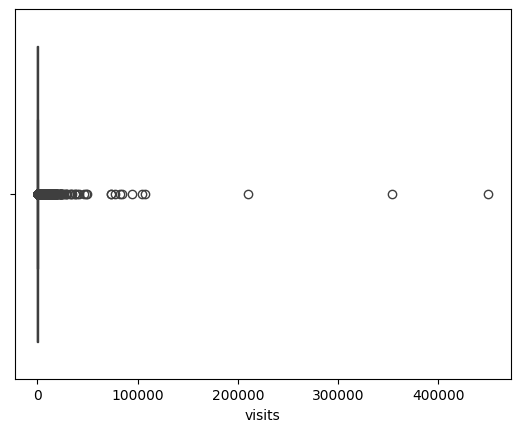

In [14]:
sns.boxplot(data=dx_freq_df, x="visits")

<Axes: ylabel='Frequency'>

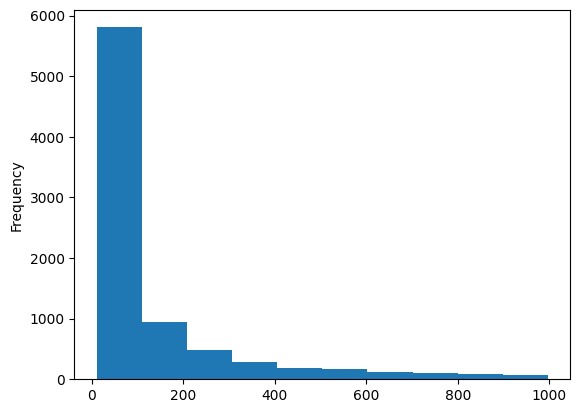

In [15]:
fig, ax = plt.subplots()
dx_freq_df[dx_freq_df['visits']<= 1000] \
    ['visits'].plot(kind='hist', ax=ax)

#### Restrict to used codes

In [16]:
dx_freq_selected = dx_freq_df[~dx_freq_df['visits'].isna()]

In [17]:
dx_freq_selected.sample(3)

,icd10_cm_code,icd10_cm_desc,ccsr_code,ccsr_desc,visits
64289,T7840XA,"T7840XA: Allergy, unspecified, initial encounter",INJ031,INJ031 Allergic reactions,98.0
64964,T82818A,T82818A: Embolism due to vascular prosthetic d...,INJ033,"INJ033 Complication of cardiovascular device, ...",381.0
8674,H6692,"H6692: Otitis media, unspecified, left ear",EAR001,EAR001 Otitis media,135.0


In [18]:
# Save the ICD code list with and without visits; we use the descriptions for refernence
# We save the visits column for later
dx_freq_selected.drop(columns='visits') \
    .to_csv(Path(setup.output_path).joinpath('REF_icd_cm_code.csv'), index=False)
dx_freq_selected.to_parquet(Path(setup.output_path).joinpath('01_ref_icd_cm_code.parquet'))

## CCSR code ref

Create a reference for the CCSR categories

In [19]:
ref_ccsr_df = dx_freq_selected.groupby('ccsr_code') \
    .agg({'ccsr_desc':'first',
          'icd10_cm_code':'count',
          'visits':'sum'}) \
    .reset_index() \
    .rename(columns={'icd10_cm_code':'icd10_cm_count'}) \
    .sort_values('ccsr_code')

In [20]:
ref_ccsr_df.shape

(441, 4)

In [21]:
ref_ccsr_df[['icd10_cm_count', 'visits']].describe()

,icd10_cm_count,visits
count,441.000000,441.000000
mean,20.641723,15202.335601
std,28.703634,47327.352937
min,1.000000,13.000000
25%,5.000000,632.000000
50%,12.000000,2782.000000
75%,25.000000,10147.000000
max,334.000000,684194.000000


The median of 12 ICD codes shows a lot of categories are fairly small.

In [22]:
ref_ccsr_df.sample(3)

,ccsr_code,ccsr_desc,icd10_cm_count,visits
376,PRG004,PRG004 Induced abortion and complications of t...,9,325.0
302,NEO037,NEO037 Female reproductive system cancers - va...,1,124.0
162,INJ017,"INJ017 Superficial injury; contusion, initial ...",58,6771.0


In [23]:
# Again - save 2 ways for a code reference and for stats
ref_ccsr_df \
     .drop(columns=['icd10_cm_count', 'visits']) \
     .to_csv(Path(setup.output_path).joinpath('REF_ccsr_code.csv'), index=False)
ref_ccsr_df.to_parquet(Path(setup.output_path).joinpath('01_ref_ccsr_code.parquet'))

## Base Dataset - Visits Drawn from Dist

Create a dataset with ICD code frequencies drawn from the distribution.  The number of visits to generate is in setup.OUTPUT_ROWS

In [24]:
print(f'Generating {setup.OUTPUT_ROWS} visits')

Generating 700000 visits


In [25]:
visits_df = dx_freq_selected[['icd10_cm_code', 'visits']] \
    .sample(n=setup.OUTPUT_ROWS, weights='visits', replace=True) \
    .drop(columns='visits')

In [26]:
visits_df.shape

(700000, 1)

In [27]:
visits_df.sample(3)

,icd10_cm_code
15435,M48061
4221,F0390
11255,K3580


In [28]:
# I will use this a lot
visits_len = len(visits_df)

## CCSR Code
Merge in the CCSR code.  This will be our hiearchical feature

In [29]:
visits_df = visits_df.merge(dx_freq_selected[['icd10_cm_code', 'ccsr_code']], 
                            how='left', on='icd10_cm_code')

In [30]:
visits_df['ccsr_code'].describe()

count     700000
unique       440
top       PNL001
freq       71798
Name: ccsr_code, dtype: object

## Import Stats for Other Features

##### Patient and visits

In [31]:
# Import the overall field summary from the public dataset
sum_stats =  pd.read_csv( "./data/sum_stats_overall.csv")

In [32]:
sum_stats['var'] = sum_stats['Variable / Label'].str.split(":").str[0]

In [33]:
sum_stats.sample(3)

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
17,110_DELIVERY: ICD-10-CM Delivery Indicator,6743716,0,1,0.1,0,685154,110_DELIVERY
2,AGE: Age in years at admission,6743095,0,90,50.8,58,342406431,AGE
53,TRAN_IN: Transfer in indicator,6708311,0,2,0.2,0,1007754,TRAN_IN


In [34]:
sum_stats.to_csv(Path(setup.output_path).joinpath('01_sum_stats.csv'), index=False)

##### Hospital related

In [35]:
hosp_stats_locteach =  pd.read_csv( "./data/hosp_locteach.csv")
hosp_stats_locteach

,HOSP_LOCTEACH,Frequency,Percent of Total
0,1: Rural,1594,38.12%
1,2: Urban nonteaching,932,22.29%
2,3: Urban teaching,1655,39.58%


In [36]:
cat_map = {'1: Rural':'Rural', '2: Urban nonteaching':'Urban_non',
           '3: Urban teaching':'Urban_teach'}

In [37]:
hosp_stats_locteach['category'] =  hosp_stats_locteach['HOSP_LOCTEACH'].apply(lambda x: cat_map[x])

In [38]:
hosp_stats_control =  pd.read_csv( "./data/hosp_control.csv")
hosp_stats_control

,Value,Label,Frequency,Percent_of_Total
0,1,"Government, non-federal (public)",805,19.25%
1,2,"Private, not-for-profit (voluntary)",2758,65.97%
2,3,"Private, investor-owned (proprietary)",618,14.78%


In [39]:
cat_map = {'Government, non-federal (public)':'Public', 
           'Private, not-for-profit (voluntary)':'Nonprofit',
           'Private, investor-owned (proprietary)':'For_profit'}

In [40]:
hosp_stats_control['category'] =  hosp_stats_control['Label'].apply(lambda x: cat_map[x])

##### Set the seed

In [41]:
rng = np.random.default_rng(23)

## Binary features

Set features according to their proportion in the AHRQ dataset.  In some cases, e.g. sex, this will be nonsense as the codes won't match the categories.

##### Function to set the variable

In [42]:
def get_binary_ser(name = 'FEMALE', 
                   rng=rng,
                   stats_df = sum_stats,
                   nrow = visits_len):
    var_rate= stats_df[stats_df['var'] == name]['Mean'].iloc[0]
    return get_binary_ser_rate(rng, name, nrow, var_rate)

In [43]:
def get_binary_ser_rate(rng=rng,
                        name = 'FEMALE', 
                        nrow = visits_len,
                        rate = 0.5, 
                        index=None):
    nrow=int(nrow)
    return pd.Series(rng.choice([0,1],
                                replace=True,
                                size = nrow,
                                p=[1-rate, rate]),
                    index=index, name=name) 

### Female

##### Set 'FEMALE' rates - correlate with the CCSR level

In [44]:
sum_stats[sum_stats['Variable / Label'].str.contains('sex')]

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
14,FEMALE: Indicator of sex,6742490,0,1,0.6,1,3726068,FEMALE


##### Get a female rate per CCSR using a normal distribitio around the mean above

In [45]:
female_rate= sum_stats[sum_stats['var'] == 'FEMALE']['Mean'].iloc[0]

In [46]:
cssr_dep_df = pd.concat([ref_ccsr_df[['ccsr_code', 'visits']],
                       pd.Series(rng.normal(loc=female_rate, scale=0.2, size= len(ref_ccsr_df)),
                                 name='female_rate') \
                       .clip(0,1)],
                      axis=1) 

In [47]:
cssr_dep_df['female_rate'].describe()

count    441.000000
mean       0.597898
std        0.200855
min        0.000000
25%        0.455097
50%        0.599418
75%        0.742174
max        1.000000
Name: female_rate, dtype: float64

##### Apply the group rates to the visits

In [48]:
rate_dict = cssr_dep_df.set_index('ccsr_code')['female_rate'].to_dict()

In [49]:
fem_labels = pd.concat([get_binary_ser_rate(nrow=len(g), rate=rate_dict[n],
                                          index=g.index) 
                       for n, g in visits_df.groupby('ccsr_code')])

In [50]:
visits_df = pd.concat([visits_df.drop(columns='FEMALE', errors='ignore').sort_index(),
                       fem_labels.sort_index()], axis=1)

In [51]:
visits_df.shape

(700000, 3)

In [52]:
female_rate_overall = visits_df['FEMALE'].mean()
print(f"The patients are {female_rate_overall:%} female")

The patients are 61.235000% female


### Weekend status

In [53]:
rate= sum_stats[sum_stats['var'] == 'AWEEKEND']['Mean'].iloc[0]
print(f"The weekend rates is {rate:%}")

The weekend rates is 20.000000%


In [54]:
visits_df['AWEEKEND'] = get_binary_ser('AWEEKEND')
visits_df['AWEEKEND'].value_counts(normalize=True)

AWEEKEND
0    0.800209
1    0.199791
Name: proportion, dtype: float64

### Elective indicator

In [55]:
elec_rate= sum_stats[sum_stats['var'] == 'ELECTIVE']['Mean'].iloc[0]
print(f"The elective rates is {elec_rate:%}")

The elective rates is 20.000000%


In [56]:
elec_rate_df = pd.concat([dx_freq_selected[['icd10_cm_code']],
                       pd.Series(rng.normal(loc=elec_rate, scale=0.1, size= len(dx_freq_selected)),
                                 name='elective_rate', index=dx_freq_selected.index) \
                       .clip(0,1)],
                      axis=1) 

In [57]:
elec_rate_df.to_csv(Path(setup.output_path).joinpath('01_feat_icd_based_info.csv'), index=False)

In [58]:
elec_rate_df['elective_rate'].describe()

count    9103.000000
mean        0.199984
std         0.096653
min         0.000000
25%         0.131280
50%         0.200657
75%         0.264639
max         0.559023
Name: elective_rate, dtype: float64

In [59]:
rate_dict = elec_rate_df.set_index('icd10_cm_code')['elective_rate'].to_dict()

In [60]:
elec_labels = pd.concat([get_binary_ser_rate(nrow=len(g), rate=rate_dict[n],
                                          index=g.index, name = 'ELECTIVE') 
                       for n, g in visits_df.groupby('icd10_cm_code')])

In [61]:
visits_df = pd.concat([visits_df.drop(columns='ELECTIVE', errors='ignore').sort_index(),
                       elec_labels.sort_index()], axis=1)

In [62]:
visits_df.shape

(700000, 5)

In [63]:
visits_df.sample(3)

,icd10_cm_code,ccsr_code,FEMALE,AWEEKEND,ELECTIVE
255174,Z3800,PNL001,1,0,0
484756,M800AXA,MUS013,0,0,0
52340,M1712,MUS006,1,1,0


In [64]:
dx_freq_selected.head(2)

,icd10_cm_code,icd10_cm_desc,ccsr_code,ccsr_desc,visits
7,A0100,"A0100: Typhoid fever, unspecified",DIG001,DIG001 Intestinal infection,29.0
18,A020,A020: Salmonella enteritis,DIG001,DIG001 Intestinal infection,1108.0


## One-Hot Features

Again use the public dataset descriptives to generate features - these are very low cardinality features that can be one hot encoded

In [65]:
def create_onehot(choice_ser, weight_ser,
                  feat_name = 'VAR',
                  rng = rng,
                  nrow = visits_len,
                  index = visits_df.index):
    p = (weight_ser / weight_ser.sum()).to_list()
    choice = pd.get_dummies(pd.Series(rng.choice(choice_ser, size = nrow, p=p)),
                           dtype='int', prefix=feat_name)
    
    if index is not None:
        choice.set_index(index, inplace=True)
    return choice
                  

In [66]:
control_df = create_onehot(hosp_stats_control['category'],
                                    hosp_stats_control['Frequency'],
                                    feat_name='HOSP_CONTROL')

In [67]:
control_df.shape

(700000, 3)

In [68]:
visits_df = pd.concat([visits_df,
                      create_onehot(hosp_stats_control['category'],
                                    hosp_stats_control['Frequency'],
                                    feat_name='HOSP_CONTROL')],
                      axis=1)

In [69]:
visits_df.sample(3)

,icd10_cm_code,ccsr_code,FEMALE,AWEEKEND,ELECTIVE,HOSP_CONTROL_For_profit,HOSP_CONTROL_Nonprofit,HOSP_CONTROL_Public
428128,E1010,END003,1,1,0,0,1,0
204318,O6981X0,PRG024,1,0,0,0,1,0
605844,S72141A,INJ006,1,0,0,0,1,0


In [70]:
visits_df['HOSP_CONTROL_Public'].mean()

np.float64(0.19251142857142858)

## Age

Do a simple clipped normal distribution 

In [71]:
sum_stats[sum_stats['var'] == 'AGE']

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
2,AGE: Age in years at admission,6743095,0,90,50.8,58,342406431,AGE


Mean is similar ish to the median.  I will do a normal dist.  with std about 20 years.  Note this will be nonsense for many cases - newborn codes, etc.

In [72]:
age_mean = sum_stats[sum_stats['var'] == 'AGE']['Mean'].iloc[0]
age_max = sum_stats[sum_stats['var'] == 'AGE']['Maximum'].iloc[0]

In [73]:
visits_df['AGE'] = rng.normal(loc=age_mean, scale=20, size=visits_len) \
    .clip(0, age_max) \
    .round(1)

In [74]:
visits_df['AGE'].describe()

count    700000.000000
mean         50.659834
std          19.465862
min           0.000000
25%          37.300000
50%          50.800000
75%          64.300000
max          90.000000
Name: AGE, dtype: float64

<Axes: >

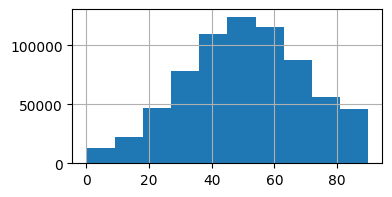

In [75]:
visits_df['AGE'].hist(figsize=(4,2))

## LOS

Visits are selected to either have a clipped normal distribution or a long exponential tail.

The split depends a bit on CSSR category

In [76]:
sum_stats[sum_stats['var'] == 'LOS']

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
23,LOS: Length of stay (cleaned),6741564,0,365,5.1,3,34149183,LOS


In [77]:
los_center = sum_stats[sum_stats['var'] == 'LOS']['Median'].iloc[0]
los_max = sum_stats[sum_stats['var'] == 'LOS']['Maximum'].iloc[0]
los_min = 1

#### Get the split fraction by CSSR

In [78]:
cssr_dep_df = pd.concat([cssr_dep_df.drop(columns='los_dist_split', errors='ignore'),
                       pd.Series(rng.normal(loc=0.9, scale=0.4, size= len(cssr_dep_df)),
                                 name='los_dist_split') \
                       .clip(0.01,0.99)],
                      axis=1) 

In [79]:
cssr_dep_df.sample(3)

,ccsr_code,visits,female_rate,los_dist_split
409,RSP010,28255.0,0.248016,0.585475
97,EYE008,1180.0,0.312035,0.504735
99,EYE012,589.0,0.666827,0.990000


In [80]:
cssr_dep_df['los_dist_split'].describe()

count    441.000000
mean       0.798237
std        0.252674
min        0.010000
25%        0.652688
50%        0.941919
75%        0.990000
max        0.990000
Name: los_dist_split, dtype: float64

In [81]:
cssr_dep_df.to_csv(Path(setup.output_path).joinpath('01_feat_ccsr_based_info.csv'), index=False)

In [82]:
cssr_dep_dict = cssr_dep_df.set_index('ccsr_code')['los_dist_split'].to_dict()

In [83]:
# Get the combined indices

In [84]:
grouped = visits_df.groupby('ccsr_code')
norm_idx = []
exp_idx = []
for n, g in grouped:
    if (len(g.index)*cssr_dep_dict[n] < 10):
        norm_idx.extend(g.index)
        continue
    this_norm_idx, this_exp_idx = train_test_split(g.index, train_size=cssr_dep_dict[n])
    norm_idx.extend(this_norm_idx)
    exp_idx.extend(this_exp_idx)

In [85]:
#norm_idx, exp_idx = train_test_split(visits_df.index, train_size=0.85)
print(f"{len(norm_idx)} shortish visits, {len(exp_idx)} extra long")

519506 shortish visits, 180494 extra long


Most cases: normally distributed but truncated / mostly short.  Truncate to 1. Use the median as the norm dist mean to keep it compact

In [97]:
los_norm_ser = pd.Series(rng.normal(loc=los_center, scale=5, size=len(norm_idx)),
                        index=norm_idx).clip(los_min, los_max)

In [98]:
los_norm_ser.describe()

count    519506.000000
mean          4.146533
std           3.570261
min           1.000000
25%           1.000000
50%           2.994268
75%           6.364305
max          28.273170
dtype: float64

For the exponential cases, have a long tail

In [99]:
los_exp_ser = pd.Series(rng.exponential(scale=(los_max/4), size=len(exp_idx)),
                    index=exp_idx) \
    .clip(los_min, los_max)

In [100]:
los_exp_ser.describe()

count    180494.000000
mean         89.706820
std          84.365463
min           1.000000
25%          26.373525
50%          63.159300
75%         126.912021
max         365.000000
dtype: float64

In [101]:
los_ser = pd.concat([los_norm_ser, los_exp_ser], axis=0) \
    .rename('LOS')

<Axes: >

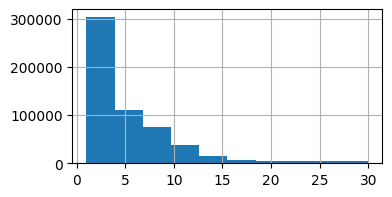

In [102]:
los_ser[los_ser < 30].hist(figsize=(4,2))

<Axes: >

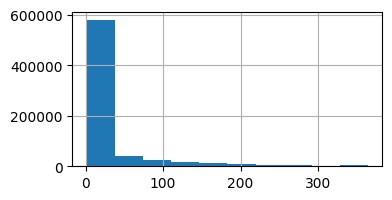

In [103]:
los_ser.hist(figsize=(4,2))

In [104]:
visits_df = pd.concat([visits_df.drop(columns='LOS', errors='ignore').sort_index(), 
                       los_ser.sort_index()], axis=1)

In [105]:
visits_df['LOS'] = visits_df['LOS'].round()

In [106]:
visits_df['LOS'].describe()

count    700000.000000
mean         26.205880
std          56.971624
min           1.000000
25%           1.000000
50%           5.000000
75%          12.000000
max         365.000000
Name: LOS, dtype: float64

## Save
We have our features!  Create a "visit ID" and save

In [107]:
visits_df.describe()

,FEMALE,AWEEKEND,ELECTIVE,HOSP_CONTROL_For_profit,HOSP_CONTROL_Nonprofit,HOSP_CONTROL_Public,AGE,LOS
count,700000.000000,700000.000000,700000.000000,700000.000000,700000.000000,700000.000000,700000.000000,700000.000000
mean,0.612350,0.199791,0.183817,0.148174,0.659314,0.192511,50.659834,26.205880
std,0.487214,0.399844,0.387335,0.355273,0.473940,0.394273,19.465862,56.971624
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,37.300000,1.000000
50%,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,50.800000,5.000000
75%,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,64.300000,12.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,90.000000,365.000000


In [108]:
visits_df.reset_index(inplace=True, names='VISIT_ID')
visits_df['VISIT_ID'] = visits_df['VISIT_ID'].astype('str').str.zfill(8)

In [109]:
visits_df.sample(3)

,VISIT_ID,icd10_cm_code,ccsr_code,FEMALE,AWEEKEND,ELECTIVE,HOSP_CONTROL_For_profit,HOSP_CONTROL_Nonprofit,HOSP_CONTROL_Public,AGE,LOS
206647,00206647,O4292,PRG029,0,0,0,0,1,0,48.7,5.0
272912,00272912,R5381,SYM007,1,0,0,0,1,0,47.2,1.0
243143,00243143,A419,INF002,1,1,0,0,1,0,6.7,7.0


In [110]:
visits_df.to_parquet(Path(setup.output_path).joinpath('01_DATA_visits_features.parquet'))